# Plain vs Highway vs ResNet na CIFAR-10

| Model | Wyjście bloku |
|---|---|
| Plain | $y = \mathrm{ReLU}(F(x))$ |
| Highway | $y = \mathrm{ReLU}(T(x) \cdot F(x) + (1 - T(x)) \cdot x)$, bramka $T$ = konwolucja 1x1 + sigmoid |
| ResNet | $y = \mathrm{ReLU}(F(x) + x)$ |

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from models import CIFARResNet

RUNS_DIR = Path("runs")
MODELS = ["plain", "highway", "resnet"]
DEPTH_COLORS = {20: "tab:blue", 32: "tab:orange", 44: "tab:green", 56: "tab:red", 110: "tab:purple"}
PAPER_RESNET = {20: 8.75, 32: 7.51, 44: 7.17, 56: 6.97, 110: 6.43}

rows, histories = [], {}
for path in sorted(RUNS_DIR.glob("*/results.json")):
    r = json.loads(path.read_text(encoding="utf-8"))
    if r["iterations"] != 64000 or r["val_split"]:
        continue
    model = CIFARResNet(r["model"], r["depth"])
    rows.append({
        "model": r["model"],
        "depth": r["depth"],
        "params": sum(p.numel() for p in model.parameters()),
        "train_err": r["final_train_err"],
        "test_err": r["test_err"],
        "gates": r.get("test_gate_means"),
    })
    histories[(r["model"], r["depth"])] = pd.read_csv(path.parent / "history.csv")

results = pd.DataFrame(rows).sort_values(["model", "depth"]).reset_index(drop=True)
results.drop(columns="gates").round(2)

,model,depth,params,train_err,test_err
0,highway,20,286186,0.63,8.35
1,highway,56,902410,0.47,11.35
2,plain,20,269722,1.17,9.49
3,plain,32,464154,1.46,9.78
4,plain,56,853018,4.41,13.81
5,resnet,20,269722,0.81,8.31
6,resnet,32,464154,0.24,7.90
7,resnet,56,853018,0.17,8.00


## Wyniki

Błąd (%) na końcu treningu. Highway ma trochę więcej parametrów niż Plain/ResNet (bramki 1x1).

In [ ]:
def pivot(values):
    return results.pivot(index="depth", columns="model", values=values).reindex(columns=MODELS).round(2)

print("Test error (%)")
display(pivot("test_err"))
print("Train error (%)")
display(pivot("train_err"))
print("Parameters")
display(pivot("params").astype("Int64"))

Test error (%)


model,plain,highway,resnet
depth,,,
20,9.49,8.35,8.31
32,9.78,NaN,7.90
56,13.81,11.35,8.00


Train error (%)


model,plain,highway,resnet
depth,,,
20,1.17,0.63,0.81
32,1.46,NaN,0.24
56,4.41,0.47,0.17


Parameters


model,plain,highway,resnet
depth,,,
20,269722,286186,269722
32,464154,<NA>,464154
56,853018,902410,853018


## Porównanie z artykułem

In [3]:
resnet = results[results.model == "resnet"].set_index("depth")
comparison = pd.DataFrame({"ours": resnet.test_err, "paper": pd.Series(PAPER_RESNET)}).dropna()
comparison["diff"] = comparison.ours - comparison.paper
comparison.round(2)

,ours,paper,diff
20,8.31,8.75,-0.44
32,7.90,7.51,0.39
56,8.00,6.97,1.03


## Krzywe uczenia

Linia przerywana: błąd treningowy, ciągła: błąd testowy.

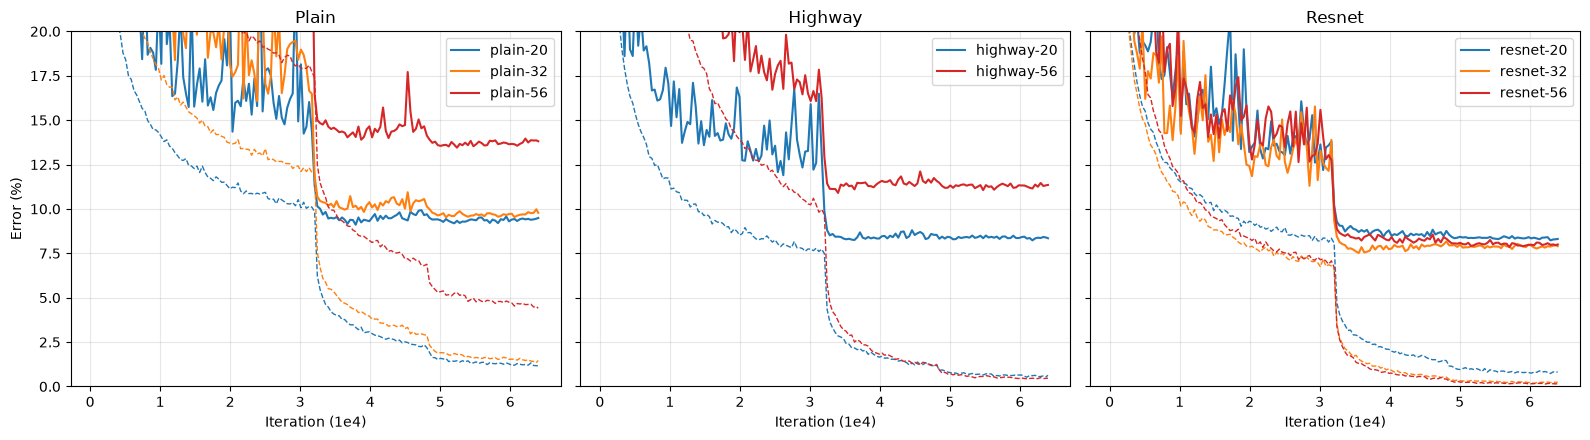

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, model in zip(axes, MODELS):
    for (name, depth), history in sorted(histories.items()):
        if name != model:
            continue
        x = history.iteration / 1e4
        color = DEPTH_COLORS[depth]
        ax.plot(x, history.train_err, "--", color=color, linewidth=1)
        ax.plot(x, history.test_err, color=color, linewidth=1.5, label=f"{model}-{depth}")
    ax.set(title=model.capitalize(), xlabel="Iteration (1e4)", ylim=(0, 20))
    ax.grid(alpha=0.3)
    ax.legend()
axes[0].set_ylabel("Error (%)")
fig.tight_layout()
plt.show()

## Błąd w zależności od głębokości

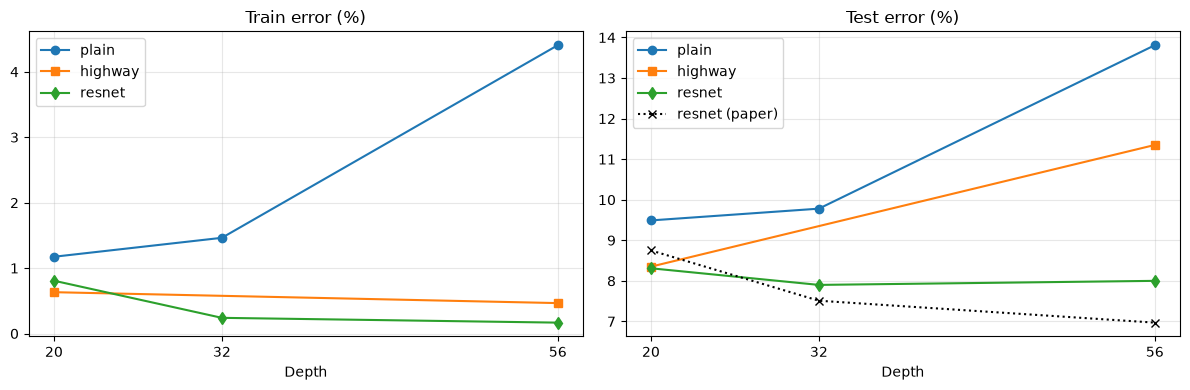

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for model, marker in zip(MODELS, "osd"):
    subset = results[results.model == model]
    axes[0].plot(subset.depth, subset.train_err, marker=marker, label=model)
    axes[1].plot(subset.depth, subset.test_err, marker=marker, label=model)

paper_depths = sorted(set(PAPER_RESNET) & set(results.depth))
axes[1].plot(paper_depths, [PAPER_RESNET[d] for d in paper_depths], "k:", marker="x", label="resnet (paper)")

for ax, title in zip(axes, ["Train error (%)", "Test error (%)"]):
    ax.set(title=title, xlabel="Depth", xticks=sorted(results.depth.unique()))
    ax.grid(alpha=0.3)
    ax.legend()
fig.tight_layout()
plt.show()

## Bramki Highway

Średnia wartość bramki $T(x)$ w każdym bloku na zbiorze testowym. $T \approx 0$ oznacza, że blok przepuszcza wejście bez zmian, $T \approx 1$, że całkowicie je przekształca. Na starcie $T = \sigma(-2) \approx 0.12$ (linia przerywana). Kolory oznaczają etapy sieci (16 / 32 / 64 filtry).

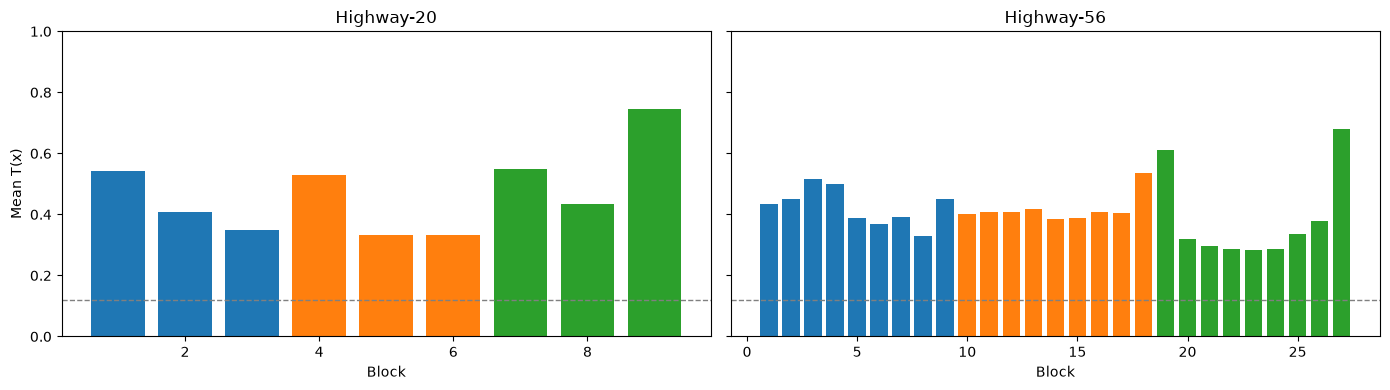

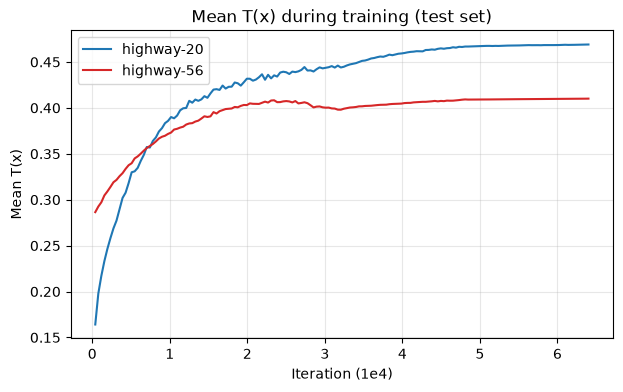

In [6]:
highway = results[results.model == "highway"]
fig, axes = plt.subplots(1, len(highway), figsize=(14, 4), sharey=True, squeeze=False)
for ax, (_, run) in zip(axes[0], highway.iterrows()):
    gates = run.gates
    per_stage = len(gates) // 3
    colors = [f"C{i // per_stage}" for i in range(len(gates))]
    ax.bar(range(1, len(gates) + 1), gates, color=colors)
    ax.axhline(0.119, color="gray", linestyle="--", linewidth=1)
    ax.set(title=f"Highway-{run.depth}", xlabel="Block", ylim=(0, 1))
axes[0][0].set_ylabel("Mean T(x)")
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
for (name, depth), history in sorted(histories.items()):
    if name != "highway":
        continue
    gate_columns = [c for c in history.columns if c.startswith("gate_")]
    ax.plot(history.iteration / 1e4, history[gate_columns].mean(axis=1), color=DEPTH_COLORS[depth], label=f"highway-{depth}")
ax.set(title="Mean T(x) during training (test set)", xlabel="Iteration (1e4)", ylabel="Mean T(x)")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

## Wnioski

- **Degradacja w sieciach plain.** Plain-56 ma wyższy błąd niż Plain-20 nie tylko na teście (13.8% vs 9.5%), ale też na zbiorze treningowym (4.4% vs 1.2%). Głębsza sieć jest trudniejsza do optymalizacji — dokładnie to, co pokazuje rys. 6 w artykule.
- **ResNet rozwiązuje ten problem.** Wraz z głębokością błąd treningowy ResNetu spada (0.8% → 0.2%), a testowy utrzymuje się na poziomie ~8% lub spada. Przy 56 warstwach ResNet jest o 5.8 p.p. lepszy od sieci plain.
- **Zgodność z artykułem.** ResNet-20 jest blisko wyniku z artykułu (8.31% vs 8.75%); ResNet-32 i 56 wypadają ok. 0.4–1 p.p. gorzej. Pojedynczy przebieg na seed + drobne różnice implementacyjne (np. BatchNorm liczony na 128 obrazach zamiast 64 na GPU) mogą to tłumaczyć. Główny trend jest odtworzony.
- **Highway vs ResNet.** Przy 20 warstwach Highway działa tak samo dobrze jak ResNet (8.35% vs 8.31%). Przy 56 warstwach jest wyraźnie gorszy (11.35% vs 8.0%) — optymalizuje się wolniej (przed spadkiem lr błąd treningowy ~10% vs ~7%) i gorzej uogólnia. Bramka może "przymknąć" skrót, a wtedy gradient nie płynie już bez przeszkód. Stały, zawsze otwarty skrót ResNetu jest prostszy i skaluje się lepiej z głębokością, mimo braku dodatkowych parametrów.
- **Bramki Highway** w trakcie treningu rosną z 0.12 do średnio ~0.47 (Highway-20) i ~0.41 (Highway-56), a w pojedynczych blokach od ~0.3 do ~0.7: sieć faktycznie używa przekształceń, a nie tylko przepuszcza wejście. Najwyższą bramkę ma ostatni blok sieci (~0.7). Głębsza sieć ma niższe bramki, czyli każdy blok przekształca mniej, a więcej przepuszcza.